In [1]:
import pandas as pd
import numpy as np


In [3]:
import pandas as pd

df = pd.read_csv(r"C:\Users\hp\Downloads\archive\Titanic-Dataset.csv")

df.head()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
df.shape

(891, 12)

In [5]:
print(df.isnull().sum())

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [6]:
print(df[["Survived", "Pclass", "Sex", "Age", "Fare", "Embarked"]].head())

   Survived  Pclass     Sex   Age     Fare Embarked
0         0       3    male  22.0   7.2500        S
1         1       1  female  38.0  71.2833        C
2         1       3  female  26.0   7.9250        S
3         1       1  female  35.0  53.1000        S
4         0       3    male  35.0   8.0500        S


In [7]:
df["Age"] = df["Age"].fillna(df["Age"].median())

df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

print(df[["Age", "Embarked"]].isnull().sum())

Age         0
Embarked    0
dtype: int64


In [8]:
df["Sex"] = df["Sex"].map({
    "male": 0,
    "female": 1
})

df["Embarked"] = df["Embarked"].map({
    "S": 0,
    "C": 1,
    "Q": 2
})

print(df[["Sex", "Embarked"]].head())

   Sex  Embarked
0    0         0
1    1         1
2    1         0
3    1         0
4    0         0


In [9]:
X = df[["Pclass", "Sex", "Age", "Fare", "Embarked"]]

y = df["Survived"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (891, 5)
Target shape: (891,)


In [24]:
X = X.fillna(X.median())

print(X.isnull().sum())

Pclass        0
Sex         891
Age           0
Fare          0
Embarked    891
dtype: int64


In [28]:
print(df["Sex"].unique())
print(df["Embarked"].unique())
print(df[["Sex", "Embarked"]].head())

[nan]
[nan]
   Sex  Embarked
0  NaN       NaN
1  NaN       NaN
2  NaN       NaN
3  NaN       NaN
4  NaN       NaN


In [31]:
df = pd.read_csv(r"C:\Users\VICTUS\Downloads\archive\Titanic-Dataset.csv")

# Missing values fill karna
df["Age"] = df["Age"].fillna(df["Age"].median())
df["Fare"] = df["Fare"].fillna(df["Fare"].median())
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

# Categories ko numeric banana
df["Sex"] = df["Sex"].map({"male": 0, "female": 1})
df["Embarked"] = df["Embarked"].map({"S": 0, "C": 1, "Q": 2})

# Features aur target banana
X = df[["Pclass", "Sex", "Age", "Fare", "Embarked"]]
y = df["Survived"]

print(X.isnull().sum())

Pclass      0
Sex         0
Age         0
Fare        0
Embarked    0
dtype: int64


In [32]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (712, 5)
Testing data: (179, 5)


In [33]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [34]:
y_pred = model.predict(X_test)

print(y_pred[:10])

[0 0 0 1 1 1 1 0 1 1]


In [35]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 79.33 %


In [36]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.81      0.84      0.83       105
           1       0.76      0.73      0.74        74

    accuracy                           0.79       179
   macro avg       0.79      0.78      0.79       179
weighted avg       0.79      0.79      0.79       179



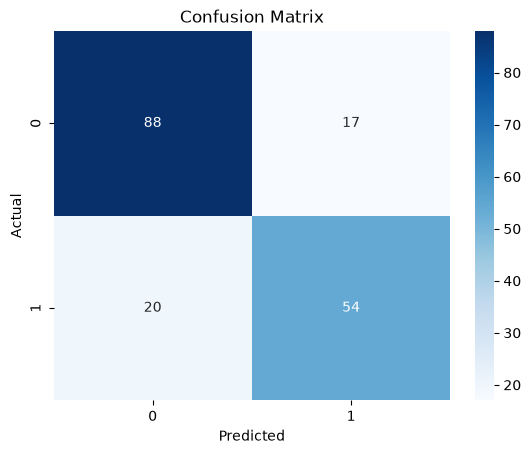

In [37]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [38]:
import pandas as pd

passenger = pd.DataFrame(
    [[3, 1, 22, 7.25, 0]],
    columns=["Pclass", "Sex", "Age", "Fare", "Embarked"]
)

prediction = model.predict(passenger)

if prediction[0] == 1:
    print("Passenger is predicted to Survive")
else:
    print("Passenger is predicted Not to Survive")

Passenger is predicted to Survive


In [15]:
from sklearn.model_selection import train_test_split

X = df[["Pclass", "Sex", "Age", "Fare", "Embarked"]]
y = df["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (712, 5)
Testing data: (179, 5)


In [16]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train, y_train)

print("Decision Tree training completed!")

Decision Tree training completed!


In [17]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train, y_train)

print("Decision Tree training completed!")

Decision Tree training completed!


In [18]:
from sklearn.metrics import accuracy_score

y_pred = dt_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Decision Tree Accuracy:", accuracy * 100, "%")

Decision Tree Accuracy: 77.6536312849162 %


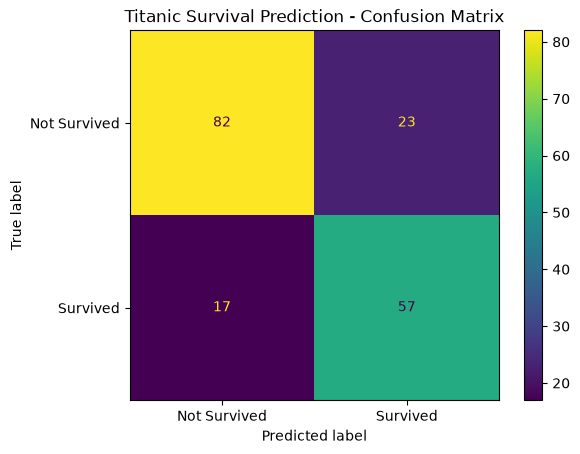

In [19]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Survived", "Survived"]
)

display.plot()
plt.title("Titanic Survival Prediction - Confusion Matrix")
plt.show()

In [20]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.83      0.78      0.80       105
           1       0.71      0.77      0.74        74

    accuracy                           0.78       179
   macro avg       0.77      0.78      0.77       179
weighted avg       0.78      0.78      0.78       179



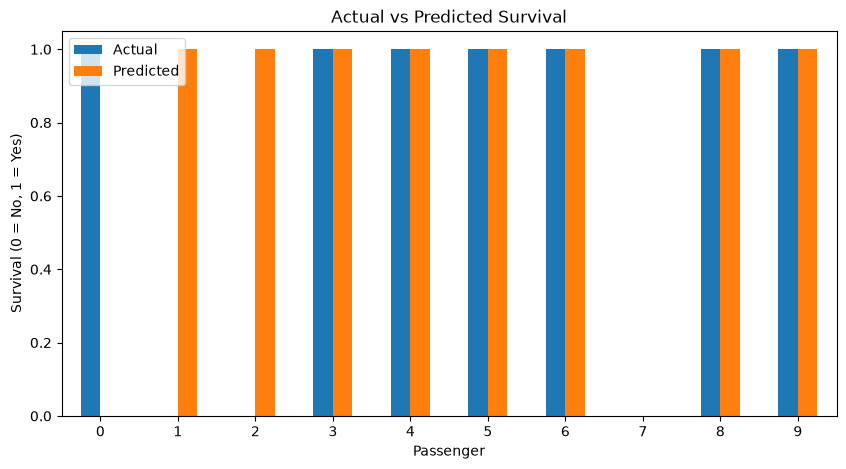

In [21]:
import pandas as pd
import matplotlib.pyplot as plt

comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

comparison.head(10).plot(kind="bar", figsize=(10, 5))

plt.title("Actual vs Predicted Survival")
plt.xlabel("Passenger")
plt.ylabel("Survival (0 = No, 1 = Yes)")
plt.xticks(rotation=0)
plt.legend()
plt.show()

In [22]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": dt_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance)

    Feature  Importance
1       Sex    0.311480
3      Fare    0.300627
2       Age    0.232912
0    Pclass    0.130825
4  Embarked    0.024156


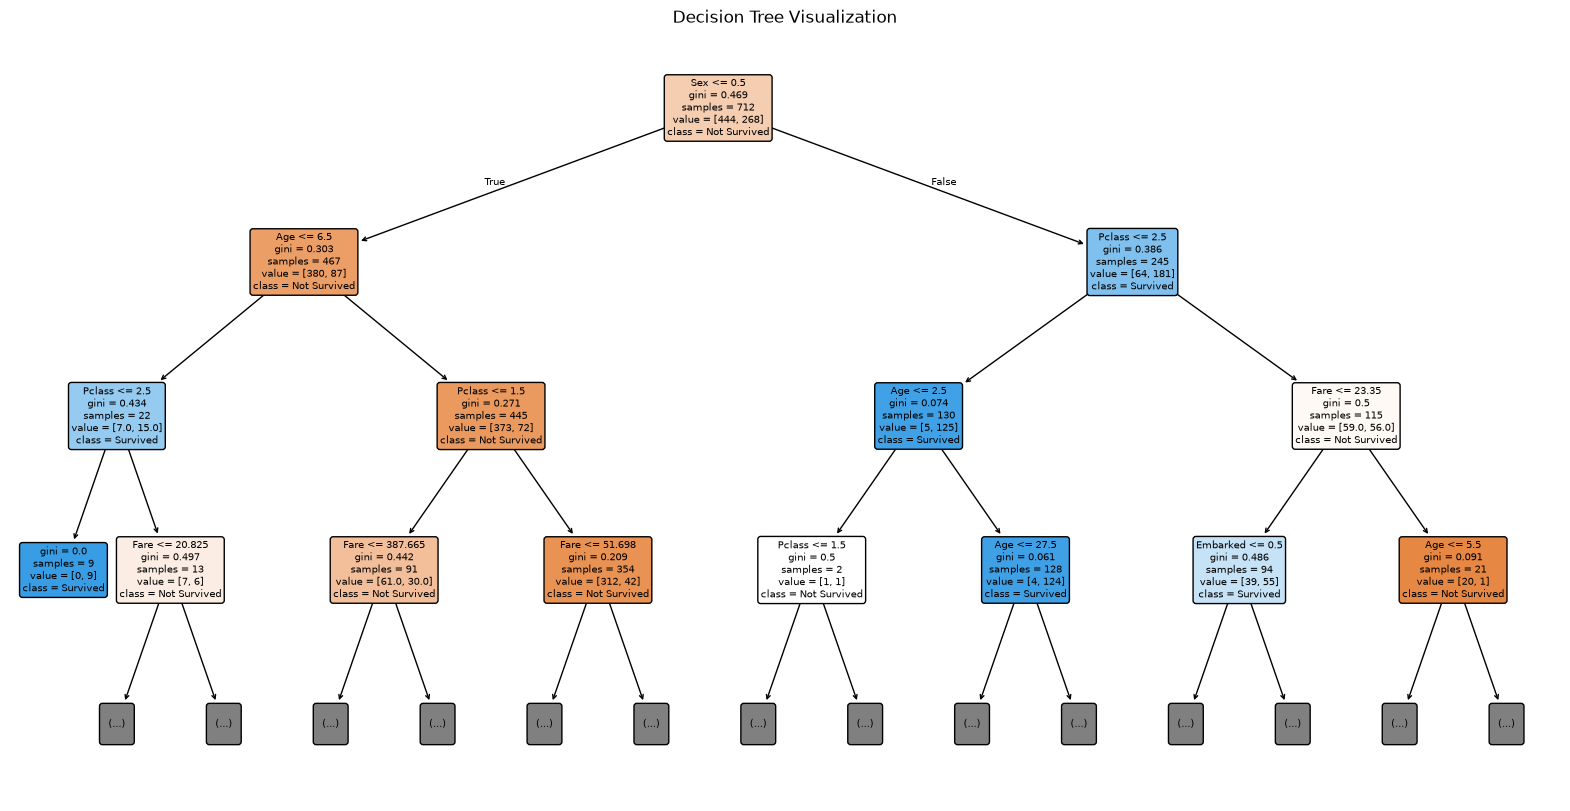

In [23]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(20, 10))

plot_tree(
    dt_model,
    feature_names=X.columns,
    class_names=["Not Survived", "Survived"],
    filled=True,
    rounded=True,
    max_depth=3
)

plt.title("Decision Tree Visualization")
plt.show()

In [24]:
new_passenger = pd.DataFrame({
    "Pclass": [3],
    "Sex": [0],
    "Age": [25],
    "Fare": [10],
    "Embarked": [0]
})

prediction = dt_model.predict(new_passenger)

if prediction[0] == 1:
    print("Passenger may have survived.")
else:
    print("Passenger may not have survived.")

Passenger may not have survived.


## Conclusion

In this project, I developed a Titanic Survival Prediction model using the Decision Tree Classifier.

I performed data preprocessing, handled missing values, converted categorical data into numerical values, and divided the dataset into training and testing sets.

I trained the model and evaluated its performance using accuracy, confusion matrix, and classification report.

This project helped me understand the basic concepts of Machine Learning, classification, model training, and prediction using Python.